### 4.1.2

In [46]:
'''>>>>> start CodeP3.2F25
    V.P. Carey ME249, Fall 2025

Intro to Neural Network Modeling 
Keras model for PV power system'''

#import useful packages
import keras
import pandas as pd
from keras.models import Sequential
import numpy as np
import keras.backend as kb
import tensorflow as tf
#the follwoing 2 lines are only needed for Mac OS machines
import os
os.environ['KMP_DUPLICATE_LIB_OK']='True'


# ===== PART 1: Define raw data first, convert temp to Kelvin, then calculate median values =====
# Raw input data: Air temp (degC), ID (W/sqm), load resistance (ohms)
xdata_celcius = [[-10.0, 1550, 4.464],  
  [-10.0, 1850, 4.464], 
  [10.0, 1550, 4.464], 
  [10.0, 1850, 4.464], 
  [30.0, 1550, 4.464], 
  [30.0, 1850, 4.464], 
  [-10.0, 1550, 6.696], 
  [-10.0, 1850, 6.696], 
  [10.0, 1550, 6.695], 
  [10.0, 1850, 6.696], 
  [30.0, 1550, 6.696], 
  [30.0, 1850, 6.698], 
  [-10.0, 1550, 8.928], 
  [-10.0, 1850, 8.928],   
  [10.0, 1550, 8.928], 
  [10.0, 1850, 8.928], 
  [30.0, 1550, 8.928], 
  [30.0, 1850, 8.928],

### x Data from Code 3.1
  [-10.0, 350, 4.464], 
  [-10.0, 650, 4.464], 
  [-10.0, 950, 4.464], 
  [-10.0, 1250, 4.464], 
  [10.0, 350, 4.464], 
  [10.0, 650, 4.464], 
  [10.0, 950, 4.464], 
  [10.0, 1250, 4.464], 
  [30.0, 350, 4.464], 
  [30.0, 650, 4.464], 
  [30.0, 950, 4.464], 
  [30.0, 1250, 4.466], 
  [-10.0, 350, 6.696], 
  [-10.0, 650, 6.696], 
  [-10.0, 950, 6.696], 
  [-10.0, 1250, 6.696], 
  [10.0, 350, 6.696], 
  [10.0, 650, 6.696], 
  [10.0, 950, 6.696], 
  [10.0, 1250, 6.696], 
  [30.0, 350, 6.696], 
  [30.0, 650, 6.696], 
  [30.0, 950, 6.696], 
  [30.0, 1250, 6.696], 
  [-10.0, 350, 8.928], 
  [-10.0, 650, 8.928], 
  [-10.0, 950, 8.928], 
  [-10.0, 1250, 8.928], 
  [10.0, 350, 8.928], 
  [10.0, 650, 8.928], 
  [10.0, 950, 8.928], 
  [10.0, 1250, 8.928], 
  [30.0, 350, 8.928], 
  [30.0, 650, 8.928], 
  [30.0, 950, 8.928], 
  [30.0, 1250, 8.928]] 


#Part 1 output HI FLUX DATA: load voltage (V) and Power out (W)
ydata_raw = [[26.1, 152.8], 
 [26.5, 172.7], 
 [27.9, 191.4], 
 [28.3, 198.0], 
 [29.6, 217.8], 
 [30.1, 224.4],  
 [26.9, 118.8], 
 [27.2, 122.1], 
 [28.8, 136.4], 
 [29.1, 139.6], 
 [30.6, 154.0], 
 [31.0, 158.4],  
 [27.3, 92.4], 
 [27.6, 94.6], 
 [29.2, 105.6], 
 [29.6, 107.8], 
 [31.1, 119.9], 
 [31.5, 123.2],
### y Data from 3.1
 [18.9, 80.3], 
 [23.5, 124.6], 
 [24.8, 138.6], 
 [25.6, 146.9], 
 [19.2, 83.1], 
 [25.0, 140.5], 
 [26.5, 157.6], 
 [27.3, 167.5],  
 [19.4, 84.7], 
 [26.4, 156.7], 
 [28.1, 177.7], 
 [29.0, 189.4],
 [22.4, 75.2], 
 [24.8, 92.2], 
 [25.8, 99.7], 
 [26.4, 104.6], 
 [23.6, 83.7], 
 [26.5, 104.9], 
 [27.6, 113.8], 
 [28.3, 119.6], 
 [24.8, 92.0], 
 [28.1, 118.2], 
 [29.3, 128.8], 
 [30.1, 135.5],  
 [23.5, 62.2], 
 [25.4, 72.5], 
 [26.3, 77.6], 
 [26.9, 81.1],  
 [25.0, 70.3], 
 [27.1, 82.7], 
 [28.1, 88.7], 
 [28.7, 92.8],  
 [26.5, 78.6], 
 [28.8, 93.5], 
 [29.9, 100.5], 
 [30.6, 105.2]] 


# Convert temperature from Celsius to Kelvin (K = degC + 273.15)
xdata_kelvin= [[row[0] + 273.15, row[1], row[2]] for row in xdata_celcius]

print("===== Temperature Conversion =====")
print("First 3 samples (Celsius -> Kelvin):")
for i in range(3):
    print(f"  {xdata_celcius[i][0]:6.2f} °C  ->  {xdata_kelvin[i][0]:6.2f} K")
print()


# Convert to numpy arrays and calculate medians
xarray = np.array(xdata_kelvin)
yarray = np.array(ydata_raw)

# Calculate input variable medians from data
Tamed = np.median(xarray[:, 0])   # Air temperature median (K)
IDmed = np.median(xarray[:, 1])   # Irradiance (ID) median (W/sqm)
RLmed = np.median(xarray[:, 2])   # Load resistance median (ohms)

# Calculate output variable medians from data
VLmed = np.median(yarray[:, 0])   # Load voltage (VL) median (V)
Wdmed = np.median(yarray[:, 1])   # Power output (Wd) median (W)

print("===== Calculated Median Values =====")
print(f"Temperature median: {Tamed:.2f} K")
print(f"Irradiance median: {IDmed:.2f} W/sqm")
print(f"Load resistance median: {RLmed:.4f} ohms")
print(f"Voltage median: {VLmed:.2f} V")
print(f"Power median: {Wdmed:.2f} W\n")

# ===== PART 2: Create normalized input data array =====
# Normalize input data by dividing by medians
xdata = []
for row in xdata_kelvin:
    xdata.append([row[0]/Tamed, row[1]/IDmed, row[2]/RLmed])

xarray = np.array(xdata)
print("===== Normalized Input Data =====")
print("First 5 rows (normalized):")
print(xarray[:5])
print(f"Input shape: {xarray.shape}\n")

# ===== PART 3: Create normalized output data array =====
# Normalize output data by dividing by medians
ydata = []
for row in ydata_raw:
    ydata.append([row[0]/VLmed, row[1]/Wdmed])

yarray = np.array(ydata)
print("===== Normalized Output Data =====")
print("First 5 rows (normalized):")
print(yarray[:5])
print(f"Output shape: {yarray.shape}\n")

# ===== PART 4: Split data into training (2/3) and validation (1/3) sets =====
# Set random seed for reproducibility
np.random.seed(42)

# Generate random indices and shuffle them
total_samples = len(xarray)
indices = np.arange(total_samples)
np.random.shuffle(indices)

# Calculate split point (2/3 for training, 1/3 for validation)
split_point = int(2/3 * total_samples)

# Split indices
train_indices = indices[:split_point]
val_indices = indices[split_point:]

# Create training and validation sets
x_train = xarray[train_indices]
y_train = yarray[train_indices]
x_val = xarray[val_indices]
y_val = yarray[val_indices]

print("===== Data Split =====")
print(f"Total samples: {total_samples}")
print(f"Training set size: {len(x_train)} ({len(x_train)/total_samples*100:.1f}%)")
print(f"Validation set size: {len(x_val)} ({len(x_val)/total_samples*100:.1f}%)")
print(f"\nTraining input shape: {x_train.shape}")
print(f"Training output shape: {y_train.shape}")
print(f"Validation input shape: {x_val.shape}")
print(f"Validation output shape: {y_val.shape}\n")



===== Temperature Conversion =====
First 3 samples (Celsius -> Kelvin):
  -10.00 °C  ->  263.15 K
  -10.00 °C  ->  263.15 K
   10.00 °C  ->  283.15 K

===== Calculated Median Values =====
Temperature median: 283.15 K
Irradiance median: 1100.00 W/sqm
Load resistance median: 6.6960 ohms
Voltage median: 27.25 V
Power median: 116.00 W

===== Normalized Input Data =====
First 5 rows (normalized):
[[0.92936606 1.40909091 0.66666667]
 [0.92936606 1.68181818 0.66666667]
 [1.         1.40909091 0.66666667]
 [1.         1.68181818 0.66666667]
 [1.07063394 1.40909091 0.66666667]]
Input shape: (54, 3)

===== Normalized Output Data =====
First 5 rows (normalized):
[[0.95779817 1.31724138]
 [0.97247706 1.4887931 ]
 [1.02385321 1.65      ]
 [1.03853211 1.70689655]
 [1.08623853 1.87758621]]
Output shape: (54, 2)

===== Data Split =====
Total samples: 54
Training set size: 36 (66.7%)
Validation set size: 18 (33.3%)

Training input shape: (36, 3)
Training output shape: (36, 2)
Validation input shape: (1

In [47]:
# define neural network model

#As seen below, we have created four dense layers. 
#A dense layer is a layer in neural network that’s fully connected. 
#In other words, all the neurons in one layer are connected to all other neurons in the next layer.
#In the first layer, we need to provide the input shape, which is 1 in our case. 
#The activation function we have chosen is elu, which stands for exponential linear unit. .

from keras import backend as K
#initialize weights with values between -0.2 and 0.5
# initializer = keras.initializers.RandomUniform(minval= -0.2, maxval=0.5)
initializer = keras.initializers.RandomUniform(minval= -0.2, maxval=0.5)

model = keras.Sequential([
    keras.layers.Dense(6, activation='elu', input_shape=[3],  kernel_initializer=initializer),
    
    keras.layers.Dense(6, activation='elu',  kernel_initializer=initializer),
    keras.layers.Dense(9, activation='elu', kernel_initializer=initializer),
    keras.layers.Dense(13, activation='elu',  kernel_initializer=initializer),
    keras.layers.Dense(7, activation='elu',  kernel_initializer=initializer),

    keras.layers.Dense(2,  kernel_initializer=initializer)
  ])


In [48]:
#We’re using RMSprop as our optimizer here. RMSprop stands for Root Mean Square Propagation. 
#It’s one of the most popular gradient descent optimization algorithms for deep learning networks. 
#RMSprop is an optimizer that’s reliable and fast.
#We’re compiling the mode using the model.compile function. The loss function used here 
#is mean squared error. After the compilation of the model, we’ll use the fit method with ~500 epochs.
#Number of epochs can be varied.

#from tf.keras import optimizers
# rms = keras.optimizers.RMSprop(0.020)
rms = keras.optimizers.RMSprop(0.001)
model.compile(loss='mean_absolute_error',optimizer=rms)


In [63]:
#After the compilation of the model, we’ll use the fit method with 500 epochs.
#I started with epochs value of 100 and then tested the model after training. 
#The prediction was not that good. Then I modified the number of epochs to 200 and tested the model again. 
#Accuracy had improved slightly, but figured I’d give it one more try. Finally, at 500 epochs 
#I found acceptable prediction accuracy.

#The fit method takes three parameters; namely, x, y, and number of epochs. 
#During model training, if all the batches of data are seen by the model once, 
#we say that one epoch has been completed.

# Add an early stopping callback
es = keras.callbacks.EarlyStopping(
    monitor='loss', 
    mode='min', 
    patience = 80, 
    restore_best_weights = True, 
    verbose=1)
# Add a checkpoint where loss is minimum, and save that model
mc = keras.callbacks.ModelCheckpoint('best_model.keras', monitor='loss', 
                     mode='min',  verbose=1, save_best_only=True)

historyData = model.fit(x_train,y_train,epochs=800,callbacks=[es])

loss_hist = historyData.history['loss']
#The above line will return a dictionary, access it's info like this:
best_epoch = np.argmin(historyData.history['loss']) + 1
print ('best epoch = ', best_epoch)
print('smallest loss =', np.min(loss_hist))

model.save('./best_model_4.1.2.keras')

Epoch 1/800
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0381
Epoch 2/800
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0654
Epoch 3/800
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0372
Epoch 4/800
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0623
Epoch 5/800
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0484
Epoch 6/800
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0331
Epoch 7/800
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0432
Epoch 8/800
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0579
Epoch 9/800
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0651
Epoch 10/800
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0325
Epoch 11/800
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0413
Epoch 12/800
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0477
Epoch 13/800
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0596
Epoch 14/800
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0464
Epoch 15/800
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0463
Epoch 16/800
2/2 ━━

In [64]:
# This line of code can be used to reconstruct the saved model.
recon_model = keras.models.load_model("best_model_4.1.2.keras")
# the name of the model is now "recon_model". You can then use this model to do predictions for comparisons.
# See the previous project for code to do the comparisons.

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
row [0] data:  T1=  263.15 , ID=  1550.0 , RL=  4.464 , power=  152.8 ,  predicted power =  159.48783111572266
row [1] data:  T1=  263.15 , ID=  1850.0 , RL=  4.464 , power=  172.7 ,  predicted power =  173.38339710235596
row [2] data:  T1=  283.15 , ID=  1550.0 , RL=  4.464 , power=  191.4 ,  predicted power =  176.77375888824463
row [3] data:  T1=  283.15 , ID=  1850.0 , RL=  4.464 , power=  198.0 ,  predicted power =  190.7103672027588
row [4] data:  T1=  303.15 , ID=  1550.0 , RL=  4.464 , power=  217.8 ,  predicted power =  194.09533596038818
row [5] data:  T1=  303.15 , ID=  1850.0 , RL=  4.464 , power=  224.4 ,  predicted power =  208.04405784606934
row [6] data:  T1=  263.15 , ID=  1550.0 , RL=  6.696 , power=  118.8 ,  predicted power =  113.15663647651672
row [7] data:  T1=  263.15 , ID=  1850.0 , RL=  6.696 , power=  122.1 ,  predicted power =  123.50975036621094
row [8] data:  T1=  283.15 , ID=  1550.0 , RL=  6.695 , power=  136.4 ,  pr

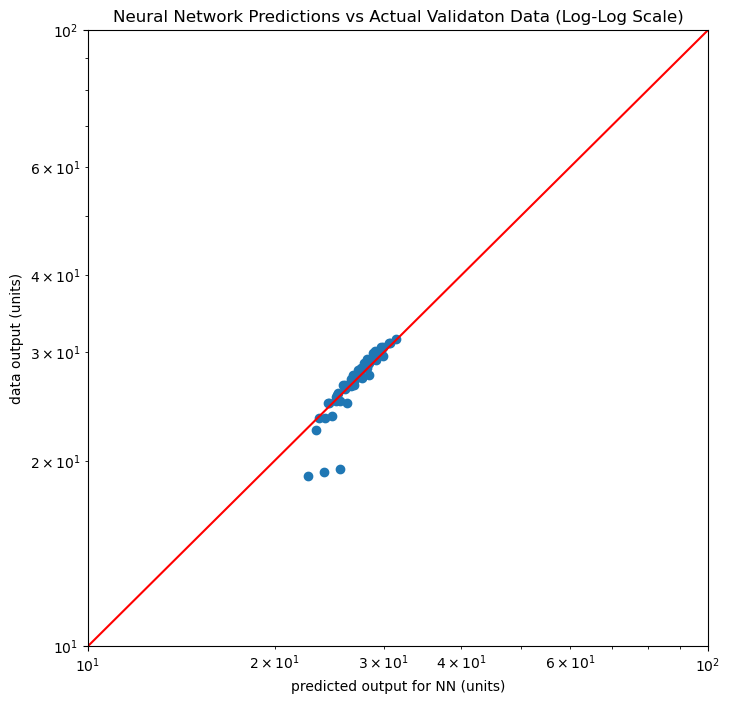

In [65]:
test = []
outpt=[]
predictions = model.predict(xarray)

#put in a loop to print comparison for all data points
for i in range(len(xarray)):
    test = [[xarray[i][0], xarray[i][1], xarray[i][2]]]
    testarray = np.array(test)
    outpt = model.predict(testarray, verbose=0)
    print('row [' + str(i) + '] data:  T1= ', xarray[i][0]*Tamed, ', ID= ', xarray[i][1]*IDmed, \
        ', RL= ', xarray[i][2]*RLmed, ', power= ', yarray[i][1]*Wdmed, \
        ',  predicted power = ', outpt[0][1]*Wdmed)

#SETTING UP PLOT
%matplotlib inline
# importing the required module
import matplotlib.pyplot as plt 
plt.rcParams['figure.figsize'] = [8, 8] # for square canvas 
#========
'''CALCULATE PREDICTED VALUES AND RETRIEVE DATA VALUES TO PLOT'''
# Denormalize for plotting
predictions_denorm = predictions[:, 0] * VLmed
actual_denorm = yarray[:, 0] * VLmed

plt.scatter(predictions_denorm, actual_denorm)
plt.title('Neural Network Predictions vs Actual Validaton Data (Log-Log Scale)')
plt.xlabel('predicted output for NN (units)') 
plt.ylabel('data output (units)')
plt.loglog()
plt.xlim(xmax=100, xmin=10)
plt.ylim(ymax=100, ymin=10)
# Generate red y=x line using logspace for proper log scale
x_data = np.logspace(np.log10(1.0), np.log10(100.0), num=100)
y_data = x_data
plt.plot(x_data, y_data, color='red')
plt.show()

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
row [0] data:  T1=  0.9293660603920184 , ID=  1.4090909090909092 , RL=  0.6666666666666667 , power=  152.8 ,  predicted power =  119.25553607940674
row [1] data:  T1=  0.9293660603920184 , ID=  1.6818181818181819 , RL=  0.6666666666666667 , power=  172.7 ,  predicted power =  91.30022096633911
row [2] data:  T1=  1.0 , ID=  1.4090909090909092 , RL=  0.6666666666666667 , power=  191.4 ,  predicted power =  83.96248054504395
row [3] data:  T1=  1.0 , ID=  1.6818181818181819 , RL=  0.6666666666666667 , power=  198.0 ,  predicted power =  86.3238525390625
row [4] data:  T1=  1.0706339396079816 , ID=  1.4090909090909092 , RL=  0.6666666666666667 , power=  217.8 ,  predicted power =  72.45755410194397
row [5] data:  T1=  1.0706339396079816 , ID=  1.6818181818181819 , RL=  0.6666666666666667 , power=  224.4 ,  predicted power =  208.04405784606934
row [6] data:  T1=  0.9293660603920184 , ID=  1.4090909090909092 , RL=  1.0 , power=  118.8 ,  predicted powe

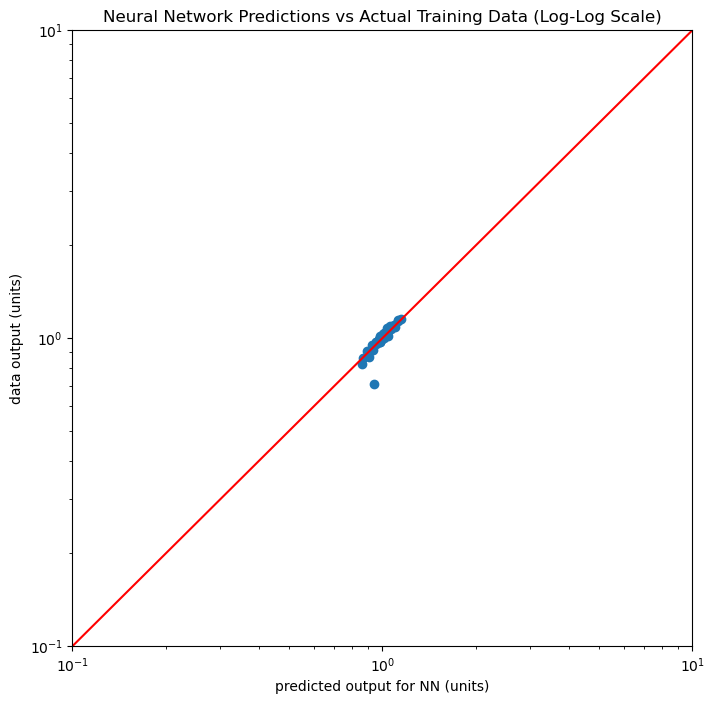

In [66]:
test = []
outpt=[]
predictions = model.predict(x_train)

#put in a loop to print comparison for all data points
for i in range(len(x_train)):
    test = [[x_train[i][0], x_train[i][1], x_train[i][2]]]
    testarray = np.array(test)
    outpt = model.predict(testarray, verbose=0)
    print('row [' + str(i) + '] data:  T1= ', xarray[i][0], ', ID= ', xarray[i][1], \
        ', RL= ', xarray[i][2], ', power= ', yarray[i][1]*Wdmed, \
        ',  predicted power = ', outpt[0][1]*Wdmed)

#SETTING UP PLOT
%matplotlib inline
# importing the required module
import matplotlib.pyplot as plt 
plt.rcParams['figure.figsize'] = [8, 8] # for square canvas 
#========
'''CALCULATE PREDICTED VALUES AND RETRIEVE DATA VALUES TO PLOT'''
# Denormalize for plotting
predictions_denorm = predictions[:, 0] 
actual_denorm = y_train[:, 0] 

plt.scatter(predictions_denorm, actual_denorm)
plt.title('Neural Network Predictions vs Actual Training Data (Log-Log Scale)')
plt.xlabel('predicted output for NN (units)') 
plt.ylabel('data output (units)')
plt.loglog()
plt.xlim(xmax=10, xmin=0.1)
plt.ylim(ymax=10, ymin=0.1)
# Generate red y=x line using logspace for proper log scale
x_data = np.logspace(np.log10(0.1), np.log10(10.0), num=100)
y_data = x_data
plt.plot(x_data, y_data, color='red')
plt.show()

===== Fixed Parameters =====
Air Temperature: 20.0°C = 293.15 K
===== Input Ranges =====
Load Resistance (RL): 4.0 - 8.0 Ohms (20 points)
Irradiance (ID): 500.0 - 1900.0 W/m² (20 points)
Total predictions: 400

===== Normalized Input Statistics =====
Temperature (normalized): 1.0353
Irradiance (normalized): min=0.4545, max=1.7273
Load Resistance (normalized): min=0.5974, max=1.1947

===== Power Output Statistics =====
Minimum Power: 84.87 W
Maximum Power: 213.40 W
Mean Power: 138.37 W



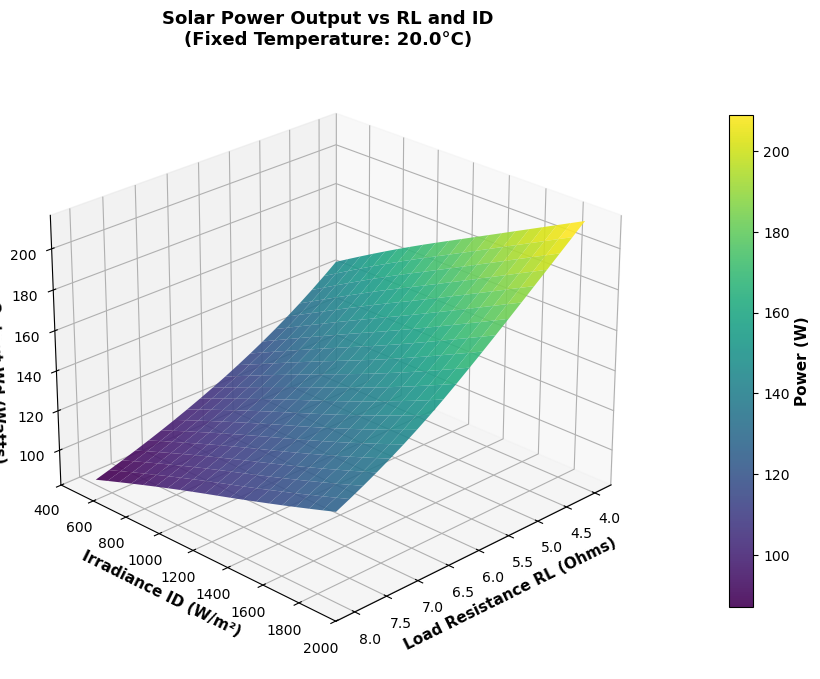

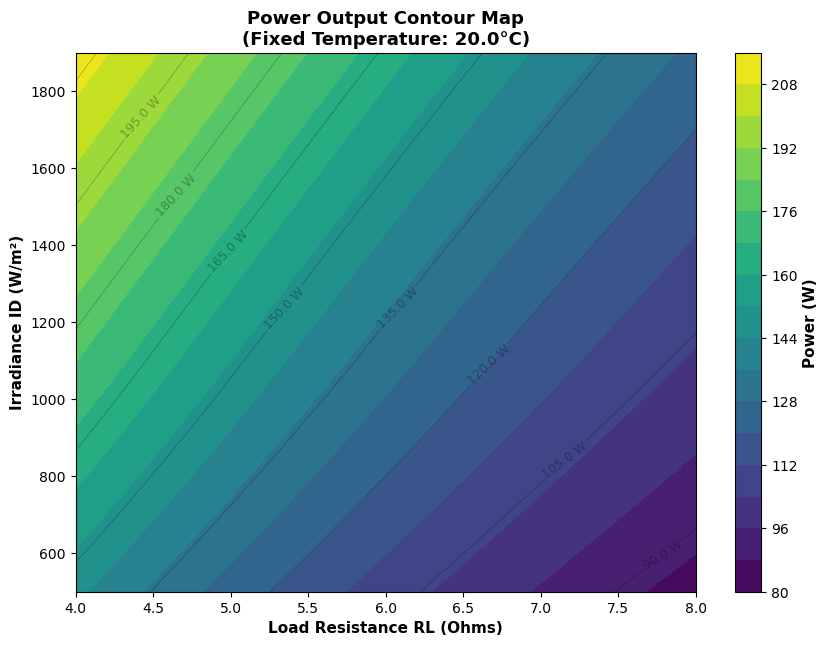

===== Sample Predictions =====

RL = 4.00 Ω, ID = 500 W/m², Power = 145.95 W
RL = 8.00 Ω, ID = 500 W/m², Power = 84.87 W
RL = 4.00 Ω, ID = 1237 W/m², Power = 182.56 W
RL = 8.00 Ω, ID = 1900 W/m², Power = 126.16 W

===== Optimal Load Resistance for Maximum Power =====

ID (W/m²)  |  Optimal RL (Ω)  |  Max Power (W)
--------------------------------------------------
   500     |       4.00      |      145.95
   795     |       4.00      |      161.38
  1089     |       4.00      |      175.72
  1384     |       4.00      |      189.41
  1679     |       4.00      |      203.12


In [67]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# ===== FIXED PARAMETER =====
T_fixed_celsius = 20.0  # Fixed air temperature in Celsius
T_fixed_kelvin = T_fixed_celsius + 273.15  # Convert to Kelvin

print("===== Fixed Parameters =====")
print(f"Air Temperature: {T_fixed_celsius}°C = {T_fixed_kelvin:.2f} K")

# ===== CREATE GRID FOR PREDICTIONS =====
# Load resistance range: 4 to 8 Ohms
RL_min, RL_max = 4.0, 8.0
RL_points = 20  # Number of points in RL direction

# Irradiance range: 500 to 1200 W/m^2
ID_min, ID_max = 500.0, 1900.0
ID_points = 20  # Number of points in ID direction

# Create meshgrid
RL_array = np.linspace(RL_min, RL_max, RL_points)
ID_array = np.linspace(ID_min, ID_max, ID_points)
RL_mesh, ID_mesh = np.meshgrid(RL_array, ID_array)

print("===== Input Ranges =====")
print(f"Load Resistance (RL): {RL_min} - {RL_max} Ohms ({RL_points} points)")
print(f"Irradiance (ID): {ID_min} - {ID_max} W/m² ({ID_points} points)")
print(f"Total predictions: {RL_points * ID_points}\n")

# ===== NORMALIZE INPUT DATA FOR MODEL =====
# Flatten meshgrid for model prediction
RL_flat = RL_mesh.flatten()
ID_flat = ID_mesh.flatten()
# Fill with fixed Kelvin temperature
T_flat = np.full_like(RL_flat, T_fixed_kelvin)

# Normalize by medians (same way as training)
RL_norm = RL_flat / RLmed
ID_norm = ID_flat / IDmed
T_norm = T_flat / Tamed

# Create input array [T, ID, RL] for the model
input_data = np.column_stack([T_norm, ID_norm, RL_norm])

print("===== Normalized Input Statistics =====")
print(f"Temperature (normalized): {T_norm[0]:.4f}")
print(f"Irradiance (normalized): min={ID_norm.min():.4f}, max={ID_norm.max():.4f}")
print(f"Load Resistance (normalized): min={RL_norm.min():.4f}, max={RL_norm.max():.4f}\n")

# ===== GET PREDICTIONS FROM MODEL =====
predictions_normalized = model.predict(input_data, verbose=0)

# Extract power output (second column) and denormalize
power_normalized = predictions_normalized[:, 1]  # Column 1 is power output
power_denorm = power_normalized * Wdmed  # Denormalize using median

# Reshape back to grid
power_grid = power_denorm.reshape(RL_mesh.shape)

print("===== Power Output Statistics =====")
print(f"Minimum Power: {power_grid.min():.2f} W")
print(f"Maximum Power: {power_grid.max():.2f} W")
print(f"Mean Power: {power_grid.mean():.2f} W\n")

# ===== CREATE 3D SURFACE PLOT =====
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# Create surface plot
surf = ax.plot_surface(RL_mesh, ID_mesh, power_grid, cmap='viridis', 
                       edgecolor='none', alpha=0.9, antialiased=True)

# Labels and title
ax.set_xlabel('Load Resistance RL (Ohms)', fontsize=11, fontweight='bold')
ax.set_ylabel('Irradiance ID (W/m²)', fontsize=11, fontweight='bold')
ax.set_zlabel('Power Output Wd (Watts)', fontsize=11, fontweight='bold')
ax.set_title(f'Solar Power Output vs RL and ID\n(Fixed Temperature: {T_fixed_celsius}°C)', 
             fontsize=13, fontweight='bold')

# Add colorbar
cbar = fig.colorbar(surf, ax=ax, pad=0.1, shrink=0.8)
cbar.set_label('Power (W)', fontsize=11, fontweight='bold')

# Adjust viewing angle for better visualization
ax.view_init(elev=25, azim=45)

plt.savefig("surface_plot.png", dpi=300, bbox_inches='tight')
plt.show()

# ===== CREATE CONTOUR PLOT =====
fig, ax = plt.subplots(figsize=(10, 7))

# Create filled contour plot
contourf = ax.contourf(RL_mesh, ID_mesh, power_grid, levels=20, cmap='viridis')
contour = ax.contour(RL_mesh, ID_mesh, power_grid, levels=10, colors='black', 
                     alpha=0.3, linewidths=0.5)

# Add contour labels
ax.clabel(contour, inline=True, fontsize=9, fmt='%.1f W')

# Labels and title
ax.set_xlabel('Load Resistance RL (Ohms)', fontsize=11, fontweight='bold')
ax.set_ylabel('Irradiance ID (W/m²)', fontsize=11, fontweight='bold')
ax.set_title(f'Power Output Contour Map\n(Fixed Temperature: {T_fixed_celsius}°C)', 
             fontsize=13, fontweight='bold')

# Add colorbar
cbar = fig.colorbar(contourf, ax=ax)
cbar.set_label('Power (W)', fontsize=11, fontweight='bold')
plt.savefig("Contour_plot.png", dpi=300, bbox_inches='tight')

plt.show()

# ===== PRINT SAMPLE PREDICTIONS =====
print("===== Sample Predictions =====\n")
sample_indices = [0, RL_points-1, RL_points*ID_points//2, RL_points*ID_points-1]
for idx in sample_indices:
    if idx < len(RL_flat):
        print(f"RL = {RL_flat[idx]:.2f} Ω, ID = {ID_flat[idx]:.0f} W/m², Power = {power_denorm[idx]:.2f} W")

# ===== OPTIONAL: Find optimal RL for maximum power at each ID =====
print("\n===== Optimal Load Resistance for Maximum Power =====\n")
print("ID (W/m²)  |  Optimal RL (Ω)  |  Max Power (W)")
print("-" * 50)
for j in range(0, ID_points, ID_points//5):
    max_power_idx = np.argmax(power_grid[j, :])
    optimal_rl = RL_array[max_power_idx]
    max_power = power_grid[j, max_power_idx]
    print(f"{ID_array[j]:6.0f}     |     {optimal_rl:6.2f}      |     {max_power:7.2f}")
